# CAT eval: where do `old` and `new` differ?

Setup mimics raw processing:

* `w0` = the scene white in linear Rec.2020, as derived from the camera WB multipliers (green-normalised, like `wbColorspaceConvert` in `module.zig`).
* `p` = camera colours, already in Rec.2020 (`decodeColour`), **not** white balanced. Here they are ColorChecker reflectances lit by a CIE D illuminant at `T` kelvin, so the camera is "perfect" and any error comes from the adaptation only.
* **Ground truth** = the same reflectances lit by D65. A correct WB/CAT should map `p` onto this.

Methods (all take `p, w0`):

| name | what | where |
|---|---|---|
| `none` | no adaptation (baseline) | |
| `gain` | `p / w0`, plain per-channel gain in Rec.2020 | |
| `new` | `cat16(p, w0, D65)` | active code in `node.color.zig`; also vkdt's **spot WB** (picker on a patch equal to `w0`, sliders `1:1:1`) |
| `old` | `vkdt_colour(p, 1/w0)` = `cat16(p, D65, 1/w0)` | vkdt `colour` module, **regular WB** (picker off), `white` sliders = `1/w0`; this is also what vkdt derives itself for a raw with `white:0:0:0` |
| `colour` | `colour`'s CAT16 von Kries on XYZ (sanity check of my `cat16`) | |

`old` and `new` are checked against the real thing (`vkdt-cli`) in sections 8 and 9; they agree to float32 round-off (~1e-6).

In [1]:
import warnings
import colour
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

warnings.filterwarnings("ignore", category=colour.utilities.ColourUsageWarning)
np.set_printoptions(precision=5, suppress=True, linewidth=140)

# ---- matrices (same values as src/math/matrices.zig and node.color.zig) ----
CAT16_M = np.array(
    [
        [0.401288, 0.650173, -0.051461],
        [-0.250268, 1.204414, 0.045854],
        [-0.002079, 0.048952, 0.953127],
    ]
)
CAT16_M_INV = np.array(
    [
        [1.86206786, -1.01125463, 0.14918677],
        [0.38752654, 0.62144744, -0.00897398],
        [-0.01584150, -0.03412294, 1.04996444],
    ]
)
XYZ_FROM_REC2020 = np.array(
    [
        [0.636958048301291, 0.1446169035862084, 0.16888097516417205],
        [0.2627002120112669, 0.6779980715188711, 0.05930171646986194],
        [0.0, 0.02807269304908745, 1.0609850577107907],
    ]
)
REC2020_FROM_XYZ = np.array(
    [
        [1.71665119, -0.35567078, -0.25336628],
        [-0.66668435, 1.61648124, 0.01576855],
        [0.01763986, -0.04277061, 0.94210312],
    ]
)
print("|M @ M_inv - I| max      :", np.abs(CAT16_M @ CAT16_M_INV - np.eye(3)).max())
print(
    "|rec2020 fwd @ inv - I|  :",
    np.abs(XYZ_FROM_REC2020 @ REC2020_FROM_XYZ - np.eye(3)).max(),
)

CONE_FROM_REC2020 = CAT16_M @ XYZ_FROM_REC2020
REC2020_FROM_CONE = REC2020_FROM_XYZ @ CAT16_M_INV
D65 = np.ones(3)
XYZ_D65 = XYZ_FROM_REC2020 @ D65

|M @ M_inv - I| max      : 7.72968000966e-09
|rec2020 fwd @ inv - I|  : 3.55095253661e-09


In [2]:
# ---- CCT <-> Rec.2020 (CIE D locus) ----
CCT_MIN, CCT_MAX = 4000.0, 25000.0


def _xy_to_uv(xy):
    x, y = xy
    d = -2.0 * x + 12.0 * y + 3.0
    return np.array([4.0 * x / d, 9.0 * y / d])


def cct_rec2020(cct):
    xy = np.asarray(colour.temperature.CCT_to_xy_CIE_D(cct), dtype=np.float64)
    return xy, REC2020_FROM_XYZ @ np.asarray(colour.xy_to_XYZ(xy), dtype=np.float64)


def rec2020_cct(rgb):
    """Linear Rec.2020 -> (CCT on the CIE D locus [K], unsigned Duv in CIE1960 uv)."""
    XYZ = XYZ_FROM_REC2020 @ np.asarray(rgb, dtype=np.float64)
    uv = _xy_to_uv(colour.XYZ_to_xy(XYZ))

    def err(t):
        return np.sum(
            (_xy_to_uv(np.asarray(colour.temperature.CCT_to_xy_CIE_D(t))) - uv) ** 2
        )

    r = minimize_scalar(
        err, bounds=(CCT_MIN, CCT_MAX), method="bounded", options={"xatol": 1e-3}
    )
    return float(r.x), float(np.sqrt(r.fun))

In [3]:
# ---- methods ----
def cat16(rgb, src, dst):
    cone = CONE_FROM_REC2020 @ rgb
    cone = cone * (CONE_FROM_REC2020 @ dst) / (CONE_FROM_REC2020 @ src)
    return REC2020_FROM_CONE @ cone


# ---- vkdt colour module, matrix path ----------------------------------------------
# src/pipe/modules/colour/main-impl.glsl + main.c (commit_params). Rec.2020 in / out.
#
#   regular WB (picker off):  rgb = cat16(rgb, vec3(1.0), params.mul.rgb)
#   spot WB    (picker on) :  rgb = cat16(rgb, picked / picked.g, params.mul.rgb)
#   params.mul = white / white.g       (`white` = the three WB sliders)
#
# cat16(rgb, src, dst) scales the cone responses by c(dst)/c(src): the sliders say what
# D65 white should turn into. With `white:0:0:0` vkdt derives them from the camera:
#   w0[j] = sum_i cam_to_rec2020[j][i] / cam_wb[i];  white = 1 / (w0 / w0.g)
def vkdt_mul(white):
    white = np.asarray(white, dtype=np.float64)
    return white / white[1]


def vkdt_white_from_w0(w0):
    """`white` sliders that make the regular path correct for a scene white `w0` (Rec.2020)."""
    w0 = np.asarray(w0, dtype=np.float64)
    return 1.0 / (w0 / w0[1])


def vkdt_colour(rgb, white, picked=None):
    src = np.ones(3) if picked is None else np.asarray(picked, dtype=np.float64) / picked[1]
    return cat16(rgb, src, vkdt_mul(white))


def m_none(p, w0):
    return np.array(p)


def m_gain(p, w0):
    return p / w0


def m_new(p, w0):
    return cat16(p, w0, D65)


def m_old(p, w0):
    return vkdt_colour(p, vkdt_white_from_w0(w0))


def m_colour(p, w0):
    to_xyz = lambda v: XYZ_FROM_REC2020 @ v
    XYZ_a = colour.adaptation.chromatic_adaptation_VonKries(
        to_xyz(p), to_xyz(w0), to_xyz(D65), transform="CAT16"
    )
    return REC2020_FROM_XYZ @ XYZ_a


METHODS = {
    "none": m_none,
    "gain": m_gain,
    "new": m_new,
    "old": m_old,
    "colour": m_colour,
}

## 0. Sanity: is my `cat16` the same as `colour`'s CAT16 von Kries?
If not, nothing below can be trusted.

In [4]:
_, w = cct_rec2020(7500)
rng = np.random.default_rng(0)
p = rng.uniform(0.05, 1.0, (100, 3))
d = np.abs(
    np.array([m_new(x, w) for x in p]) - np.array([m_colour(x, w) for x in p])
).max()
print("max |new - colour CAT16| =", d)

max |new - colour CAT16| = 9.31518195912e-09


## 1. Algebra: when are `old` and `new` the same?

With `C = CONE_FROM_REC2020` and `c(v) = C @ v`:

* `new = C^-1 . diag(c(D65) / c(w0)) . C . p`
* `old = C^-1 . diag(c(1/w0) / c(D65)) . C . p`

They are identical iff `c(1/w0) * c(w0) = c(D65)^2` per cone channel. The per-channel reciprocal (`1/w0`) is taken in **Rec.2020**, but the division happens in **cone space**; since `C` isn't diagonal, `c(1/w0) != 1/c(w0)`. So `old` is only a first-order approximation of a white balance, and it does **not** map `w0` to D65.

In [5]:
print(
    f"{'CCT':>6} | {'c(1/w0)*c(w0)/c(D65)^2 (1 = old==new)':^42} | {'old(w0)':^26} | {'new(w0)':^26}"
)
for T in (4000, 5000, 6504, 7500, 10000, 15000, 25000):
    _, w = cct_rec2020(T)
    ratio = (
        (CONE_FROM_REC2020 @ (1 / w))
        * (CONE_FROM_REC2020 @ w)
        / (CONE_FROM_REC2020 @ D65) ** 2
    )
    print(
        f"{T:>6} | {np.array2string(ratio, precision=4):^42} | {np.array2string(m_old(w, w), precision=4):^26} | {np.array2string(m_new(w, w), precision=4):^26}"
    )

   CCT |   c(1/w0)*c(w0)/c(D65)^2 (1 = old==new)    |          old(w0)           |          new(w0)          
  4000 |         [ 1.0346  1.0325  1.023 ]          | [ 0.9994  0.9928  0.9833]  |       [ 1.  1.  1.]       
  5000 |         [ 1.0075  1.0073  1.0053]          | [ 0.9947  0.9941  0.9919]  |       [ 1.  1.  1.]       
  6504 |               [ 1.  1.  1.]                | [ 1.0002  1.0002  1.0002]  |       [ 1.  1.  1.]       
  7500 |         [ 1.0013  1.0013  1.001 ]          | [ 1.0041  1.0042  1.0038]  |       [ 1.  1.  1.]       
 10000 |         [ 1.0083  1.0085  1.0064]          | [ 1.0111  1.0119  1.0093]  |       [ 1.  1.  1.]       
 15000 |         [ 1.02    1.0207  1.0158]          | [ 1.0175  1.0205  1.0143]  |       [ 1.  1.  1.]       
 25000 |         [ 1.0312  1.0326  1.0251]          | [ 1.0215  1.0275  1.0178]  |       [ 1.  1.  1.]       


## 2. The white patch itself
A patch equal to `w0` must come out as D65 (`1,1,1`, i.e. ~6507.65 K / Duv 6e-5 by `rec2020_cct`; **not** 6500 K - D65 is not exactly on the D-series locus). Anything else is a neutrality error.

In [6]:
print(f"{'T':>6} | " + " | ".join(f"{n:^38}" for n in ("gain", "new", "old")))
for T in (4000, 5000, 6504, 7500, 10000, 15000, 25000):
    _, w = cct_rec2020(T)
    cells_ = []
    for n in ("gain", "new", "old"):
        o = METHODS[n](w, w)
        c, duv = rec2020_cct(o)
        cells_.append(f"{c:7.1f}K duv={duv:.5f} maxdev={np.abs(o - 1).max():.4f}")
    print(f"{T:>6} | " + " | ".join(f"{s:^38}" for s in cells_))

     T |                  gain                  |                  new                   |                  old                  
  4000 |    6507.7K duv=0.00006 maxdev=0.0000   |    6507.7K duv=0.00006 maxdev=0.0000   |    6426.3K duv=0.00030 maxdev=0.0167  
  5000 |    6507.7K duv=0.00006 maxdev=0.0000   |    6507.7K duv=0.00006 maxdev=0.0000   |    6492.0K duv=0.00005 maxdev=0.0081  
  6504 |    6507.7K duv=0.00006 maxdev=0.0000   |    6507.7K duv=0.00006 maxdev=0.0000   |    6507.7K duv=0.00006 maxdev=0.0002  
  7500 |    6507.7K duv=0.00006 maxdev=0.0000   |    6507.7K duv=0.00006 maxdev=0.0000   |    6505.4K duv=0.00005 maxdev=0.0042  
 10000 |    6507.7K duv=0.00006 maxdev=0.0000   |    6507.7K duv=0.00006 maxdev=0.0000   |    6495.5K duv=0.00006 maxdev=0.0119  
 15000 |    6507.7K duv=0.00006 maxdev=0.0000   |    6507.7K duv=0.00006 maxdev=0.0000   |    6483.2K duv=0.00031 maxdev=0.0205  
 25000 |    6507.7K duv=0.00006 maxdev=0.0000   |    6507.7K duv=0.00006 maxdev=0.0000   |

## 3. Ground truth: ColorChecker under illuminant `T` -> D65
"Perfect camera" = Rec.2020 of XYZ under the illuminant, white normalised to G=1 like the WB multipliers. Reference = same reflectances under D65. Error is CIEDE2000 with the D65 white.

In [7]:
CMFS = colour.MSDS_CMFS["CIE 1931 2 Degree Standard Observer"]
CC = colour.SDS_COLOURCHECKERS["ColorChecker N Ohta"]
CC_NAMES = list(CC.keys())
CC_SDS = [CC[n] for n in CC_NAMES]
ILL_D65 = colour.SDS_ILLUMINANTS["D65"]
ONES = colour.SpectralDistribution(dict.fromkeys(ILL_D65.wavelengths, 1.0))
SHAPE = ILL_D65.shape


def illum_D(T):
    return colour.sd_CIE_illuminant_D_series(colour.temperature.CCT_to_xy_CIE_D(T))


def xyz_under(sd, ill):
    return colour.sd_to_XYZ(sd, CMFS, ill) / 100.0


def scene(T):
    """-> (p [24x3 camera-like Rec.2020, white G=1], w0 [3], truth [24x3 Rec.2020 under D65])"""
    ill = illum_D(T)
    w = REC2020_FROM_XYZ @ xyz_under(ONES, ill)
    g = w[1]  # green normalisation of the WB (wbColorspaceConvert)
    p = np.array([REC2020_FROM_XYZ @ xyz_under(sd, ill) for sd in CC_SDS]) / g
    truth = np.array([REC2020_FROM_XYZ @ xyz_under(sd, ILL_D65) for sd in CC_SDS])
    return p, w / g, truth


def to_lab(rgb):
    XYZ = np.maximum(rgb @ XYZ_FROM_REC2020.T, 1e-6)
    return colour.XYZ_to_Lab(XYZ, colour.XYZ_to_xy(XYZ_D65))


def de2000(a, b):
    return colour.delta_E(to_lab(a), to_lab(b), method="CIE 2000")


def run(T):
    p, w0, truth = scene(T)
    return {n: np.array([f(x, w0) for x in p]) for n, f in METHODS.items()}, truth, w0


# sanity: the "white 9.5" patch under D65 is ~neutral
_, _, tr = scene(6504)
print("reflectance-white under D65 (patch 19, 'white 9.5'):", tr[18])

p, w, tr = scene(2500)
print("1/w0:", 1 / w)
# 1/w0: [ 0.57723  1.       3.27544]

reflectance-white under D65 (patch 19, 'white 9.5'): [ 0.88699  0.88831  0.876  ]
1/w0: [ 0.57723  1.       3.27544]


mean / max dE2000 vs ground truth (24 ColorChecker patches)
     T |     none      |     gain      |      new      |      old      |    colour    
  4000 | 11.71 /19.64 |  1.03 / 2.84 |  1.73 / 3.65 |  2.00 / 4.33 |  1.73 / 3.65
  4500 |  8.69 /16.06 |  0.75 / 2.05 |  1.23 / 2.57 |  1.34 / 2.90 |  1.23 / 2.57
  5000 |  6.10 /12.26 |  0.52 / 1.39 |  0.82 / 1.71 |  0.86 / 1.85 |  0.82 / 1.71
  5500 |  3.82 / 8.32 |  0.32 / 0.85 |  0.49 / 1.02 |  0.50 / 1.07 |  0.49 / 1.02
  6000 |  1.81 / 4.24 |  0.15 / 0.39 |  0.22 / 0.46 |  0.23 / 0.47 |  0.22 / 0.46
  7000 |  1.53 / 3.87 |  0.13 / 0.33 |  0.18 / 0.38 |  0.18 / 0.38 |  0.18 / 0.38
  7500 |  2.81 / 6.81 |  0.25 / 0.62 |  0.34 / 0.71 |  0.35 / 0.71 |  0.34 / 0.71
  8500 |  4.76 /10.82 |  0.46 / 1.09 |  0.60 / 1.22 |  0.61 / 1.30 |  0.60 / 1.22
 10000 |  6.79 /14.45 |  0.69 / 1.68 |  0.87 / 1.81 |  0.90 / 1.99 |  0.87 / 1.81
 12500 |  8.88 /17.71 |  0.97 / 2.41 |  1.17 / 2.48 |  1.23 / 2.80 |  1.17 / 2.48
 15000 | 10.15 /19.50 |  1.16 / 2

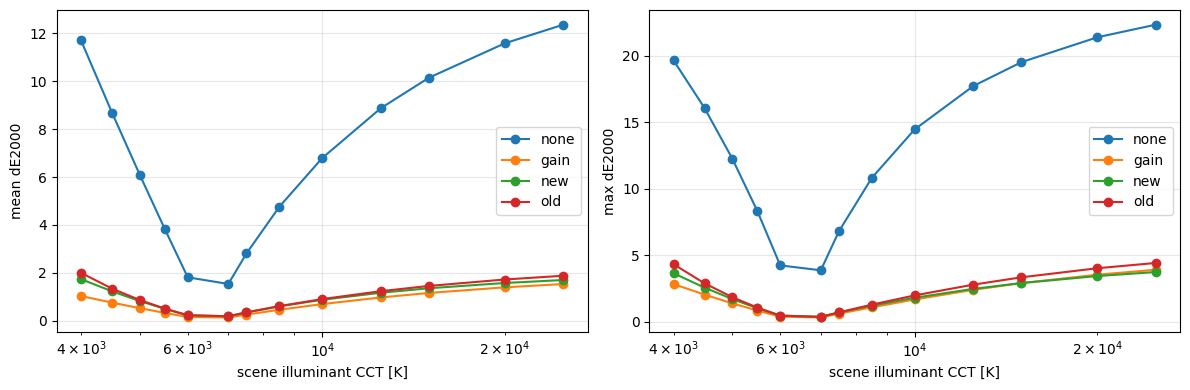

In [8]:
TS = [4000, 4500, 5000, 5500, 6000, 7000, 7500, 8500, 10000, 12500, 15000, 20000, 25000]
stats = {n: [] for n in METHODS}
for T in TS:
    out, truth, w0 = run(T)
    for n in METHODS:
        stats[n].append(de2000(out[n], truth))
stats = {n: np.array(v) for n, v in stats.items()}  # [len(TS), 24]

print("mean / max dE2000 vs ground truth (24 ColorChecker patches)")
print(f"{'T':>6} | " + " | ".join(f"{n:^13}" for n in METHODS))
for i, T in enumerate(TS):
    print(
        f"{T:>6} | "
        + " | ".join(
            f"{stats[n][i].mean():5.2f} /{stats[n][i].max():5.2f}" for n in METHODS
        )
    )

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for n in METHODS:
    if n == "colour":
        continue
    ax[0].plot(TS, [s.mean() for s in stats[n]], "o-", label=n)
    ax[1].plot(TS, [s.max() for s in stats[n]], "o-", label=n)
for a, t in zip(ax, ("mean dE2000", "max dE2000")):
    a.set_xlabel("scene illuminant CCT [K]")
    a.set_ylabel(t)
    a.set_xscale("log")
    a.grid(alpha=0.3)
    a.legend()
plt.tight_layout()
plt.show()

## 4. Per-patch errors at one illuminant
Which patches are the problem children (saturated blues/oranges usually)? Change `T`.

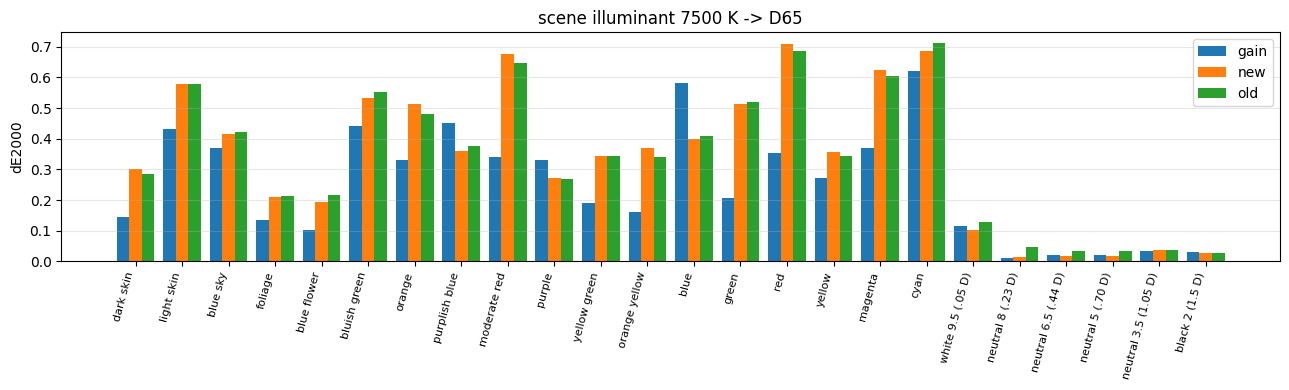

In [9]:
T = 7500
out, truth, w0 = run(T)
errs = {n: de2000(out[n], truth) for n in ("gain", "new", "old")}
fig, ax = plt.subplots(figsize=(13, 4))
x = np.arange(24)
bw = 0.27
for k, n in enumerate(errs):
    ax.bar(x + (k - 1) * bw, errs[n], bw, label=n)
ax.set_xticks(x)
ax.set_xticklabels(CC_NAMES, rotation=75, ha="right", fontsize=8)
ax.set_ylabel("dE2000")
ax.set_title(f"scene illuminant {T} K -> D65")
ax.legend()
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

## 5. Visual: one panel per method, ColorChecker layout (4x6)
First panel is the ground truth. Encoded to sRGB for display only; out-of-gamut values are clipped.

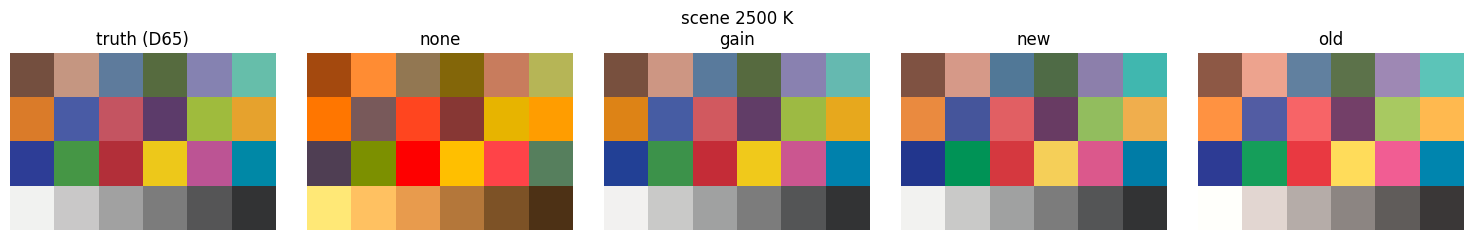

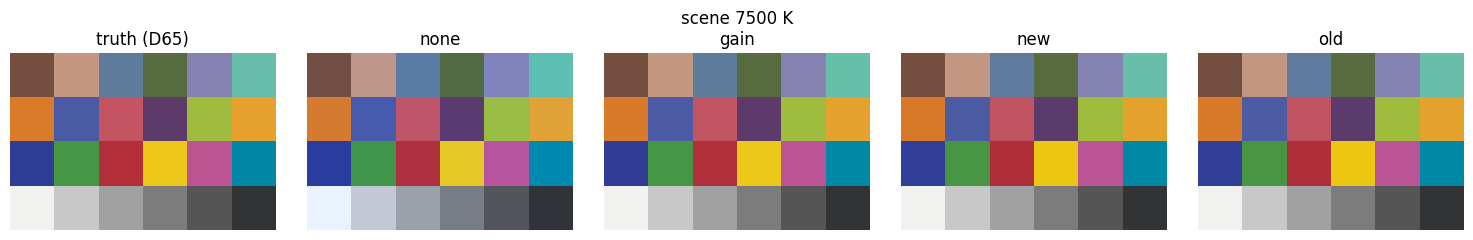

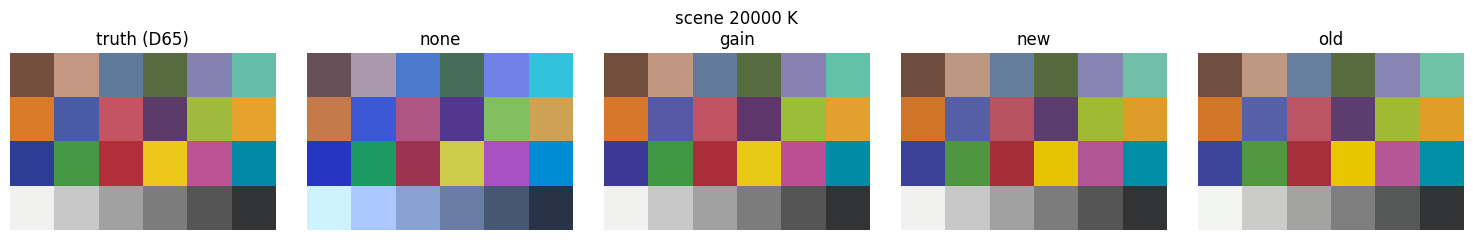

In [10]:
def srgb(rgb):
    XYZ = rgb @ XYZ_FROM_REC2020.T
    return np.clip(colour.XYZ_to_sRGB(XYZ), 0, 1)


def show(T, names=("none", "gain", "new", "old")):
    out, truth, w0 = run(T)
    rows = [("truth (D65)", truth)] + [(n, out[n]) for n in names]
    fig, ax = plt.subplots(1, len(rows), figsize=(3 * len(rows), 2.4))
    for a, (n, r) in zip(ax, rows):
        a.imshow(srgb(r).reshape(4, 6, 3), interpolation="nearest")
        a.set_title(n)
        a.axis("off")
    fig.suptitle(f"scene {T} K")
    plt.tight_layout()
    plt.show()


for T in (2500, 7500, 20000):
    show(T)

### Display chart for eyeballing (not for numbers)
The next two cells write `plot_output.exr`: the figure as drawn, i.e. **sRGB-encoded, clipped to 0..1 and 8-bit**. Fine to look at in vkdt (set `i-exr` to `prim:1 trc:2`), but it cannot check the maths: saturated or bright patches are clipped (at 2500 K the `none` white is R=2.27 in linear Rec.709 but is stored as 1.0), so vkdt cannot reproduce what the notebook computes from it. Section 8 quantifies this and provides float charts that can.

In [11]:

import OpenEXR
import Imath

def srgb_to_linear(c):
    """Convert normalized sRGB values [0, 1] to linear RGB."""
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)


def save(fig):
    # 2. Render the figure canvas to a NumPy RGBA array
    fig.canvas.draw()
    rgba_buffer = np.frombuffer(fig.canvas.tostring_argb(), dtype=np.uint8)
    rgba_buffer = rgba_buffer.reshape(
        fig.canvas.get_width_height()[::-1] + (4,)
    )  # (H, W, 4)

    # Convert ARGB to RGB float or half-float (normalize 0-1)
    rgb = rgba_buffer[:, :, 1:4].astype(np.float32) / 255.0
    # rgb = srgb_to_linear(rgb)
    h, w, _ = rgb.shape

    # Split channels for OpenEXR writer
    R = rgb[:, :, 0].tobytes()
    G = rgb[:, :, 1].tobytes()
    B = rgb[:, :, 2].tobytes()

    header = OpenEXR.Header(w, h)
    FLOAT = Imath.PixelType(Imath.PixelType.FLOAT)
    header["channels"] = {
        "R": Imath.Channel(FLOAT),
        "G": Imath.Channel(FLOAT),
        "B": Imath.Channel(FLOAT),
    }

    exr_out = OpenEXR.OutputFile("plot_output.exr", header)
    exr_out.writePixels({"R": R, "G": G, "B": B})
    exr_out.close()

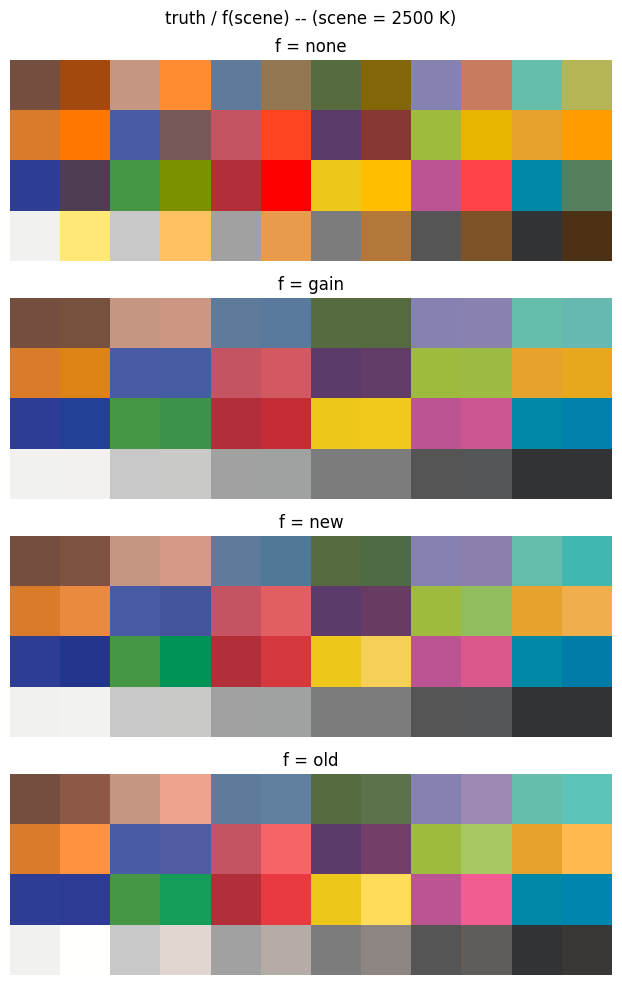

In [65]:
def show(T, names=("none", "gain", "new", "old")):
    out, truth, w0 = run(T)
    rows = [(n, out[n]) for n in names]
    fig, ax = plt.subplots(len(rows), 1, figsize=(10, 10))
    for a, (n, r) in zip(ax, rows):
        a.imshow(
            np.column_stack((srgb(truth), srgb(r))).reshape(4, 6 * 2, 3),
            interpolation="nearest",
        )
        a.set_title(f"f = {n}")
        a.axis("off")
    fig.suptitle(f"truth / f(scene) -- (scene = {T} K)")
    plt.tight_layout()
    save(fig)
    plt.show()

show(2500)
# for T in (2500, 7500, 20000):
#     show(T)

## 6. Chromaticity of the neutral ramp after adaptation
Patches 19-24 of the ColorChecker are the grey ramp; all should land on D65.

In [13]:
T = 7500
out, truth, w0 = run(T)
grey = slice(18, 24)
print(f"grey ramp, scene {T} K, CCT/Duv of the output (target ~6507.65 K, duv 6e-5)")
for n in ("none", "gain", "new", "old"):
    cs = [rec2020_cct(r) for r in out[n][grey]]
    print(f"{n:>5}: " + "  ".join(f"{c:7.1f}K/{d:.4f}" for c, d in cs))
print(
    "truth: "
    + "  ".join(f"{c:7.1f}K/{d:.4f}" for c, d in [rec2020_cct(r) for r in truth[grey]])
)

grey ramp, scene 7500 K, CCT/Duv of the output (target ~6507.65 K, duv 6e-5)
 none:  7393.7K/0.0004   7475.6K/0.0002   7517.7K/0.0001   7524.2K/0.0002   7675.8K/0.0003   7970.6K/0.0001
 gain:  6428.3K/0.0005   6483.1K/0.0002   6514.4K/0.0002   6518.8K/0.0002   6632.6K/0.0003   6841.1K/0.0001
  new:  6428.0K/0.0005   6483.4K/0.0002   6514.5K/0.0002   6518.9K/0.0002   6631.8K/0.0003   6839.8K/0.0001
  old:  6425.9K/0.0005   6481.2K/0.0002   6512.3K/0.0001   6516.7K/0.0002   6629.5K/0.0003   6837.4K/0.0001
truth:  6432.1K/0.0004   6484.5K/0.0002   6515.3K/0.0001   6519.3K/0.0002   6633.1K/0.0003   6839.7K/0.0001


## 7. A real camera white: the DSC_6765.NEF values from `module.zig`'s test
Port of `wbColorspaceConvert`: camera WB multipliers -> Rec.2020 gain. Note this passes the as-shot white through `xyz_d65_from_cam`, which is a *D65* matrix, so the white is only as correct as that matrix is at the shot illuminant. Duv tells you if the white is on the daylight locus; if it isn't (tint), the D-series ground truth above doesn't apply.

In [14]:
cam_mul = np.array([1.90625, 1.0, 1.4921875])
xyz_d65_from_cam = np.array(
    [
        [1.5699793, 0.14481506, 0.10475578],
        [0.6360732, 0.8477491, -0.221411],
        [0.12701747, -0.2259345, 1.4544346],
    ]
)


def wb_colorspace_convert(xyz_d65_from_cam, wb_coeffs_cam):
    white_cam = 1.0 / wb_coeffs_cam
    white = REC2020_FROM_XYZ @ (xyz_d65_from_cam @ white_cam)
    white = white / white[1]
    return 1.0 / white


gain = wb_colorspace_convert(xyz_d65_from_cam, cam_mul)
w0 = 1.0 / gain
print("gain (zig test expects 0.8191874, 1, 1.3340929):", gain)
print("w0 = scene white in Rec.2020:", w0)
cct, duv = rec2020_cct(w0)
print(f"scene white: {cct:.0f} K, duv={duv:.4f}")
print(
    "new(w0) =",
    m_new(w0, w0),
    "   old(w0) =",
    m_old(w0, w0),
    "   gain(w0) =",
    m_gain(w0, w0),
)

gain (zig test expects 0.8191874, 1, 1.3340929): [ 0.81919  1.       1.33409]
w0 = scene white in Rec.2020: [ 1.22072  1.       0.74957]
scene white: 4629 K, duv=0.0068
new(w0) = [ 1.  1.  1.]    old(w0) = [ 1.02526  1.0106   1.00629]    gain(w0) = [ 1.  1.  1.]


## 8. Cross-check against vkdt itself (headless `vkdt-cli`)
Graph: `i-pfm -> colour -> o-pfm`. `i-pfm` reads float32 and tags it linear Rec.2020, so `colour`'s input decode is a no-op and the output (linear Rec.2020, float) is exactly the WB/CAT stage. Two paths:

* **regular WB** (`picked:0`, `white` = `1/w0`) must equal `old`;
* **spot WB** (`picked:1`, `white` = `1:1:1`, a `pick` module on a patch that is exactly `w0`) must equal `new`.

The chart is *float, unclipped, linear Rec.2020*: the 24 ColorChecker patches a perfect camera records under illuminant `T`, one patch equal to `w0`, then a 6x6x6 cube (0, .05, .2, .5, 1, 4 per channel: black, highlights, saturated). Note `pick` stores a box as `(x0, x1, y0, y1)`.

In [15]:
# ---- headless vkdt (vkdt-cli) ----
import itertools
import os
import pathlib
import subprocess
import tempfile

VKDT_DIR = pathlib.Path(os.environ.get("VKDT_DIR", "~/Documents/c/vkdt")).expanduser()
VKDT_CLI = VKDT_DIR / "bin" / "vkdt-cli"
HAVE_VKDT = VKDT_CLI.exists()
print("vkdt-cli:", VKDT_CLI if HAVE_VKDT else "NOT FOUND - set VKDT_DIR; the vkdt checks below are skipped")


def write_pfm(path, img):
    img = np.ascontiguousarray(img, dtype="<f4")
    h, w, _ = img.shape
    with open(path, "wb") as f:
        f.write(f"PF\n{w} {h}\n-1.0\n".encode())  # negative scale = little endian; rows are not flipped
        f.write(img.tobytes())


def read_pfm(path, dtype=np.float64):
    with open(path, "rb") as f:
        assert f.readline().strip() == b"PF"
        w, h = map(int, f.readline().split())
        scale = float(f.readline())
        a = np.frombuffer(f.read(), dtype="<f4" if scale < 0 else ">f4")
    return a.reshape(h, w, 3).astype(dtype)


def vkdt_cli(graph_lines, img=None, dtype=np.float64, timeout=600):
    """Run a graph with vkdt-cli and return what its `o-pfm:main` wrote (HxWx3).

    `@DIR@` in graph_lines is a scratch directory; `img` (if given) is written there as in.pfm and
    the result is read from out.pfm."""
    with tempfile.TemporaryDirectory() as d:
        d = pathlib.Path(d)
        if img is not None:
            write_pfm(d / "in.pfm", img)
        cfg = d / "g.cfg"
        cfg.write_text("\n".join(["frames:1", "fps:0", *[l.replace("@DIR@", str(d)) for l in graph_lines]]) + "\n")
        # vkdt-cli finds its modules relative to bin/, so run from there. `-d err`: errors only.
        r = subprocess.run(
            [str(VKDT_CLI), "-g", str(cfg), "--last-frame-only", "-d", "err"],
            cwd=VKDT_DIR / "bin", capture_output=True, timeout=timeout,
        )
        if r.returncode:
            raise RuntimeError((r.stderr or r.stdout).decode()[-500:])
        return read_pfm(d / "out.pfm", dtype)


def vkdt_colour_run(img, white=(1.0, 1.0, 1.0), picked_box=None):
    """`i-pfm -> colour -> o-pfm`.

    white      the three `white` sliders of colour:01 (regular WB, picker off).
    picked_box (x0, x1, y0, y1) in 0..1 image coordinates (pick's own order): connect a `pick`
               module on the input and switch colour:01 to spot WB (`picked:1`).
    """
    pick = picked_box is not None
    lines = [
        "module:i-pfm:main",
        "module:colour:01",
        "module:o-pfm:main",
        "connect:i-pfm:main:output:colour:01:input",
        "connect:colour:01:output:o-pfm:main:input",
        "param:i-pfm:main:filename:@DIR@/in.pfm",
        "param:o-pfm:main:filename:@DIR@/out",
        "param:colour:01:matrix:1",  # use the primaries/trc that come with the image
        f"param:colour:01:white:{white[0]!r}:{white[1]!r}:{white[2]!r}:0",
        f"param:colour:01:picked:{int(pick)}",
    ]
    if pick:
        lines += [
            "module:pick:01",
            "connect:i-pfm:main:output:pick:01:input",
            "connect:pick:01:picked:colour:01:picked",
            "param:pick:01:nspots:1",
            "param:pick:01:spots:" + ":".join(repr(float(v)) for v in picked_box),
        ]
    return vkdt_cli(lines, img)

vkdt-cli: /var/home/phcreery/Documents/c/vkdt/bin/vkdt-cli


In [16]:
# ---- test charts (float, unclipped, linear Rec.2020) ----
LEVELS = (0.0, 0.05, 0.2, 0.5, 1.0, 4.0)  # black, dark, mid, 1.0 and a >1 highlight
CUBE = np.array(list(itertools.product(LEVELS, repeat=3)))  # 216 colours
PATCH, COLS = 16, 21


def chart_colours(T):
    """-> colours [N,3] (what a perfect camera records under illuminant T), w0, index of the w0 patch."""
    p, w0, _ = scene(T)
    return np.vstack([p, w0[None], CUBE]), w0, len(p)


def patch_image(colours, cols=COLS, size=PATCH):
    rows = -(-len(colours) // cols)
    img = np.zeros((rows * size, cols * size, 3), dtype=np.float32)
    for i, c in enumerate(colours):
        r, k = divmod(i, cols)
        img[r * size : (r + 1) * size, k * size : (k + 1) * size] = c
    return img


def patch_values(img, n, cols=COLS, size=PATCH):
    """Centre pixel of each of the first n patches."""
    out = np.empty((n, 3))
    for i in range(n):
        r, k = divmod(i, cols)
        out[i] = img[r * size + size // 2, k * size + size // 2]
    return out


def patch_box(i, img_shape, cols=COLS, size=PATCH, inset=0.25):
    """Picker box strictly inside patch i. pick stores spots as (x0, x1, y0, y1), 0..1 of the
    image (collect.comp: `aabb = spot * size.xxyy`)."""
    r, k = divmod(i, cols)
    h, w = img_shape[:2]
    a, b = inset * size, (1 - inset) * size
    return ((k * size + a) / w, (k * size + b) / w, (r * size + a) / h, (r * size + b) / h)


def compare(a, b):
    """-> max |a-b|, max relative error (where |b| > 1e-3), max dE2000."""
    d = np.abs(a - b)
    big = np.abs(b) > 1e-3
    return d.max(), (d[big] / np.abs(b)[big]).max(), de2000(a, b).max()

In [17]:
if HAVE_VKDT:
    print(f"{'T':>6} | {'regular WB (white=1/w0) vs old':^36} | {'spot WB (pick w0 patch) vs new':^36}")
    print(f"{'':>6} | {'max abs':>10} {'max rel':>10} {'max dE2000':>13} | {'max abs':>10} {'max rel':>10} {'max dE2000':>13}")
    for T in (2500, 4000, 7500, 15000, 25000):
        cols_, w0, iw = chart_colours(T)
        img = patch_image(cols_)
        src = patch_values(img, len(cols_))  # exactly what vkdt reads (float32)

        reg = patch_values(vkdt_colour_run(img, white=vkdt_white_from_w0(w0)), len(cols_))
        ref_old = np.array([m_old(x, w0) for x in src])

        spot = patch_values(vkdt_colour_run(img, picked_box=patch_box(iw, img.shape)), len(cols_))
        ref_new = np.array([m_new(x, src[iw]) for x in src])  # picked = the w0 patch itself

        a, b = compare(reg, ref_old), compare(spot, ref_new)
        print(f"{T:>6} | {a[0]:10.2e} {a[1]:10.2e} {a[2]:13.2e} | {b[0]:10.2e} {b[1]:10.2e} {b[2]:13.2e}")
        assert a[0] < 1e-4 and b[0] < 1e-4, "vkdt and the notebook disagree"
    print("vkdt == notebook (old: regular WB, new: spot WB)")

     T |    regular WB (white=1/w0) vs old    |    spot WB (pick w0 patch) vs new   
       |    max abs    max rel    max dE2000 |    max abs    max rel    max dE2000


  2500 |   1.37e-06   5.73e-05      4.32e-05 |   2.25e-06   4.49e-05      2.73e-05


  4000 |   8.97e-07   6.81e-05      3.31e-05 |   1.79e-06   1.33e-04      7.51e-05


  7500 |   1.62e-06   5.40e-05      1.27e-04 |   1.71e-06   2.37e-05      8.10e-05


 15000 |   1.18e-06   5.80e-05      4.47e-05 |   1.03e-06   8.48e-05      2.12e-05


 25000 |   1.42e-06   5.89e-05      2.60e-05 |   2.25e-06   2.82e-05      8.50e-05
vkdt == notebook (old: regular WB, new: spot WB)


### Why the display chart can't check this
Two things that are easy to get wrong when comparing with vkdt on a picture:

* the sliders were read off a white **patch** (`p[18]`, "white 9.5") instead of the illuminant white `w0`. The patch is not spectrally flat, so the sliders are slightly off (~1% in blue);
* the picture went through the display chart: sRGB-encoded, clipped, 8-bit. Whatever is out of Rec.709 or above 1 is gone before vkdt sees it.

Both are emulated here (numpy only; vkdt reproduces numpy exactly, see above) as the error of `old` against the exact `old`.

In [18]:
REC2020_FROM_REC709 = np.array(  # vkdt matrix_rec709_to_rec2020
    [
        [0.62750375, 0.32927542, 0.04330266],
        [0.06910828, 0.91951916, 0.0113596],
        [0.01639406, 0.08801125, 0.89538035],
    ]
)

print(f"{'T':>6} | {'white from patch (float)':^24} | {'display chart (8-bit sRGB, clipped)':^36}")
print(f"{'':>6} | {'mean / max dE2000':^24} | {'mean / max dE2000':^22} {'patches clipped':>14}")
for T in (2500, 4000, 7500, 20000):
    p, w0, truth = scene(T)
    ref = np.array([m_old(x, w0) for x in p])  # exact vkdt `old`

    a = np.array([vkdt_colour(x, vkdt_white_from_w0(p[18])) for x in p])

    disp = np.round(srgb(p) * 255) / 255
    lin = np.where(disp > 0.04045, ((disp + 0.055) / 1.055) ** 2.4, disp / 12.92)
    b = np.array([vkdt_colour(x, vkdt_white_from_w0(w0)) for x in lin @ REC2020_FROM_REC709.T])
    clipped = int(((disp == 0) | (disp == 1)).any(axis=1).sum())

    da, db = de2000(a, ref), de2000(b, ref)
    print(f"{T:>6} | {da.mean():10.2f} / {da.max():<10.2f} | {db.mean():9.2f} / {db.max():<9.2f} {clipped:>10d}/24")

     T | white from patch (float) | display chart (8-bit sRGB, clipped) 
       |    mean / max dE2000     |   mean / max dE2000    patches clipped
  2500 |       0.24 / 0.57       |      4.62 / 29.60             11/24
  4000 |       0.20 / 0.52       |      1.07 / 12.13              4/24
  7500 |       0.37 / 1.05       |      0.31 / 3.27               2/24
 20000 |       0.55 / 1.52       |      1.14 / 15.24              3/24


### Charts for the vkdt GUI
Float PFMs of the 24 ColorChecker patches, 6 columns x 4 rows (row-major, same order as `scene(T)[0]`), as a perfect camera records them under illuminant `T`: linear Rec.2020, unclipped, no gamma. Open with `i-pfm`. Regular WB: set `colour:01`'s `white` sliders to the printed values with the picker off, and the result is `old`. (Spot WB uses the colour of whatever you pick as the white; patch 18, "white 9.5", is not exactly `w0`, so that is close to `new` but not identical.) The 21-column chart with the `w0` patch and the colour cube is only for the automated check above.

In [19]:
CHART_DIR = pathlib.Path("charts")


def export_chart(T, size=100):
    p, w0, _ = scene(T)
    img = patch_image(p, cols=6, size=size)  # 6 x 4 patches
    CHART_DIR.mkdir(exist_ok=True)
    path = CHART_DIR / f"chart_{T}K.pfm"
    write_pfm(path, img)
    wh = vkdt_white_from_w0(w0)
    print(f"{path}  {img.shape[1]}x{img.shape[0]}  white sliders {wh[0]:.5f}:{wh[1]:.0f}:{wh[2]:.5f}")


for T in (2500, 7500, 15000):
    export_chart(T)

charts/chart_2500K.pfm  600x400  white sliders 0.57723:1:3.27544
charts/chart_7500K.pfm  600x400  white sliders 1.04007:1:0.88804
charts/chart_15000K.pfm  600x400  white sliders 1.15354:1:0.62091


## 9. A real raw through vkdt
`white:0:0:0` makes vkdt derive the sliders from the camera (`main.c`: `cam_to_rec2020` and the as-shot WB). Port of that in pie is `wbColorspaceConvert` (section 7). If they are the same, rendering the raw with vkdt's own white and with pie's `gain` must give the same image.

In [20]:
NEF = pathlib.Path(os.environ.get("PIE_TEST_NEF", "~/Pictures/DSC_6765.NEF")).expanduser()


def vkdt_raw(white):
    """`i-raw -> demosaic -> colour -> o-pfm`, linear Rec.2020 float32."""
    return vkdt_cli(
        [
            "module:i-raw:main",
            "module:demosaic:01",
            "module:colour:01",
            "module:o-pfm:main",
            "connect:i-raw:main:output:demosaic:01:input",
            "connect:demosaic:01:output:colour:01:input",
            "connect:colour:01:output:o-pfm:main:input",
            f"param:i-raw:main:filename:{NEF}",
            "param:o-pfm:main:filename:@DIR@/out",
            "param:colour:01:matrix:1",
            f"param:colour:01:white:{white[0]!r}:{white[1]!r}:{white[2]!r}:0",
        ],
        dtype=np.float32,
    )


if HAVE_VKDT and NEF.exists():
    gain_pie = wb_colorspace_convert(xyz_d65_from_cam, cam_mul)
    auto = vkdt_raw((0.0, 0.0, 0.0))  # vkdt's own as-shot white
    pie = vkdt_raw(tuple(float(g) for g in gain_pie))
    flat = vkdt_raw((1.0, 1.0, 1.0))  # no white balance
    print("pie gain (wbColorspaceConvert):", gain_pie)
    print(f"max |vkdt auto - vkdt(pie gain)| = {np.abs(auto - pie).max():.2e}")
    print(f"max |vkdt auto - no WB|          = {np.abs(auto - flat).max():.2e}   <- size of the effect")
    assert np.abs(auto - pie).max() < 1e-5, "pie's WB gain differs from vkdt's"
else:
    print("skipped: need vkdt-cli and", NEF)

pie gain (wbColorspaceConvert): [ 0.81919  1.       1.33409]


max |vkdt auto - vkdt(pie gain)| = 1.49e-08


max |vkdt auto - no WB|          = 1.85e-02   <- size of the effect


## Notes / things to try
* `old` is a gain in disguise: it multiplies cone responses by `c(1/w0)`; `new` divides by `c(w0)`. They agree to first order and diverge as `w0` leaves D65 (see section 1 ratios) and on saturated colours.
* To test tint, replace `illum_D(T)` with a non-daylight SD (e.g. `colour.SDS_ILLUMINANTS["FL2"]`, `"A"`) and build `w0` from it; `rec2020_cct`'s Duv will be large.
* `xyz_d65_from_cam` only exists for D65. For a real camera, interpolate DNG ColorMatrix1/2 by the scene CCT before computing `w0` (that is the standard DNG recipe).
* A display-referred chart (sRGB, clipped, 8-bit) is the wrong input for a numeric vkdt comparison; use the float PFM charts of section 8. `pick` boxes are `(x0, x1, y0, y1)`.
* `old` vs `new` is "which vkdt path": the regular WB sliders (`old`) or the picker (`new`). The two only coincide when `c(1/w0) * c(w0) = c(D65)^2`.